<a href="https://colab.research.google.com/github/DianaBarradasSanchez/Simulaci-n-ll/blob/main/PyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ajuste de Parámetros del Modelo SIR usando Enfoque Bayesiano con PyMC

El modelo epidémico **SIR** divide a una población constante $N$ en tres compartimentos:
* **Susceptibles ($S$)**: Individuos con riesgo de contraer la enfermedad[cite: 1].
* **Infectados ($I$)**: Individuos actualmente infectados capaces de transmitir la enfermedad[cite: 1].
* **Recuperados ($R$)**: Individuos recuperados con inmunidad[cite: 1].

El sistema de Ecuaciones Diferenciales Ordinarias (EDO) está dado por:

$$\frac{dS}{dt} = -\frac{\beta S I}{N}$$

$$\frac{dI}{dt} = \frac{\beta S I}{N} - \gamma I$$

$$\frac{dR}{dt} = \gamma I$$

Donde $\beta$ es la tasa de transmisión y $\gamma$ es la tasa de recuperación. El enfoque bayesiano permite estimar las distribuciones de probabilidad de estos parámetros utilizando el Teorema de Bayes junto con métodos de muestreo MCMC en PyMC.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
from scipy.integrate import solve_ivp
import pytensor.tensor as pt
from pytensor.compile.ops import as_op

# 1. Simulación de Datos Sintéticos para el Modelo SIR
N = 1000.0
I0, R0_val = 1.0, 0.0
S0 = N - I0 - R0_val
beta_real, gamma_real = 0.35, 0.10
dias = 60
t_eval = np.linspace(0, dias, dias)

def sir_edo(t, y, beta, gamma):
    S, I, R = y
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

# Generación de la solución real con ruido simulado
sol_real = solve_ivp(sir_edo, [0, dias], [S0, I0, R0_val], args=(beta_real, gamma_real), t_eval=t_eval)
np.random.seed(42)
ruido = np.random.normal(0, 8, size=dias)
obs_infectados = np.clip(sol_real.y[1] + ruido, 0, None)

### Definición del Modelo en PyMC

Para integrar la resolución numérica de la EDO dentro del grafo probabilístico de PyMC, utilizamos un operador personalizado de PyTensor (`@as_op`) que envuelve la función `solve_ivp` de SciPy. Esto permite definir las distribuciones a priori (*priors*) para $\beta$ y $\gamma$, y calcular la verosimilitud de los datos observados.

In [3]:
def resolver_sir(beta_val, gamma_val):
    sol = solve_ivp(sir_edo, [0, dias], [S0, I0, R0_val],
                    args=(beta_val, gamma_val), t_eval=t_eval)
    return sol.y[1]

@as_op(itypes=[pt.dscalar, pt.dscalar], otypes=[pt.dvector])
def pymc_sir_op(beta_v, gamma_v):
    return resolver_sir(beta_v, gamma_v)

with pm.Model() as modelo_sir:
    # Priors
    beta = pm.TruncatedNormal('beta', mu=0.3, sigma=0.15, lower=0)
    gamma = pm.TruncatedNormal('gamma', mu=0.1, sigma=0.1, lower=0)
    sigma = pm.HalfNormal('sigma', sigma=10)

    # Parámetro determinista: Número reproductivo básico R0
    R0 = pm.Deterministic('R0', beta / gamma)

    # Evaluación de la EDO
    mu_I = pymc_sir_op(beta, gamma)

    # Verosimilitud (Likelihood)
    Y_obs = pm.Normal('Y_obs', mu=mu_I, sigma=sigma, observed=obs_infectados)

    # Muestreo MCMC
    trace = pm.sample(draws=1000, tune=1000, chains=2, random_seed=42, return_inferencedata=True)

/tmp/ipykernel_1875/1273977947.py:6: FutureWarning: pytensor.as_op is deprecated and will be removed in a future release. Please use pytensor.wrap_py instead.
  @as_op(itypes=[pt.dscalar, pt.dscalar], otypes=[pt.dvector])


Output()

### Análisis e Interpretación de Resultados

Una vez ejecutado el muestreo MCMC, evaluamos el ajuste mediante las siguientes gráficas e interpretaciones:
* **Gráfica de Trazas (`az.plot_trace`):** Permite comprobar la convergencia de las cadenas.
* **Gráfica Posterior (`az.plot_posterior`):** Muestra los intervalos de credibilidad (HDI al 95%) para los parámetros.
* **Chequeo Predictivo:** Compara las curvas simuladas por la distribución a posteriori frente a los datos reales observados.

        mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
beta   0.350  0.001   0.349    0.351        0.0      0.0    1273.0    1455.0   
gamma  0.101  0.001   0.100    0.102        0.0      0.0    1207.0    1308.0   
R0     3.473  0.016   3.442    3.503        0.0      0.0    1718.0    1717.0   

       r_hat  
beta     1.0  
gamma    1.0  
R0       1.0  


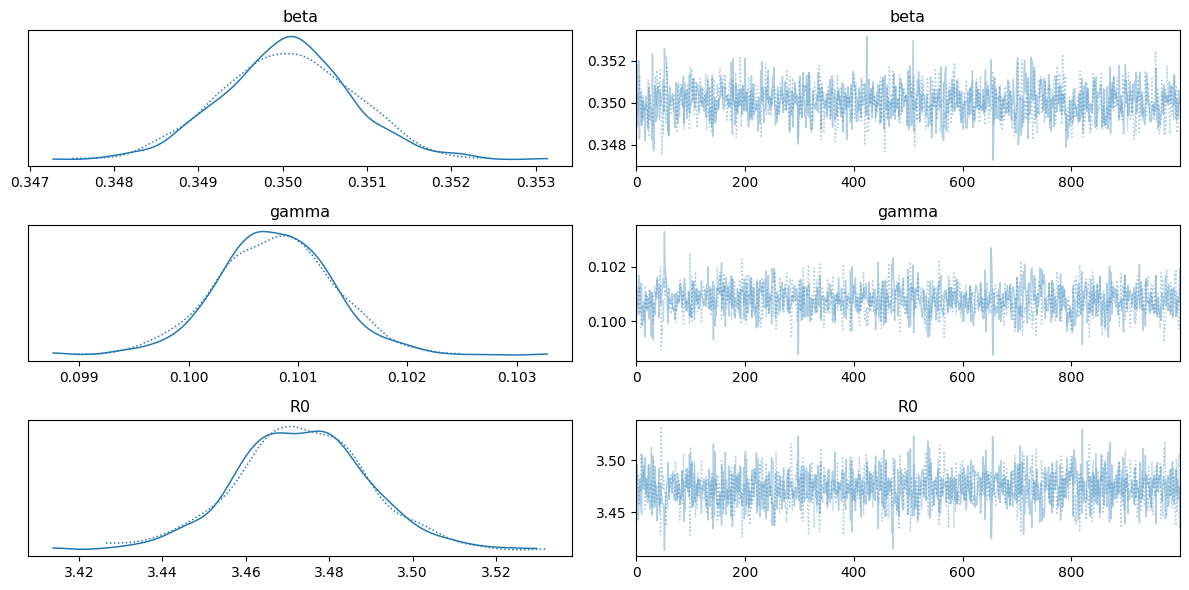

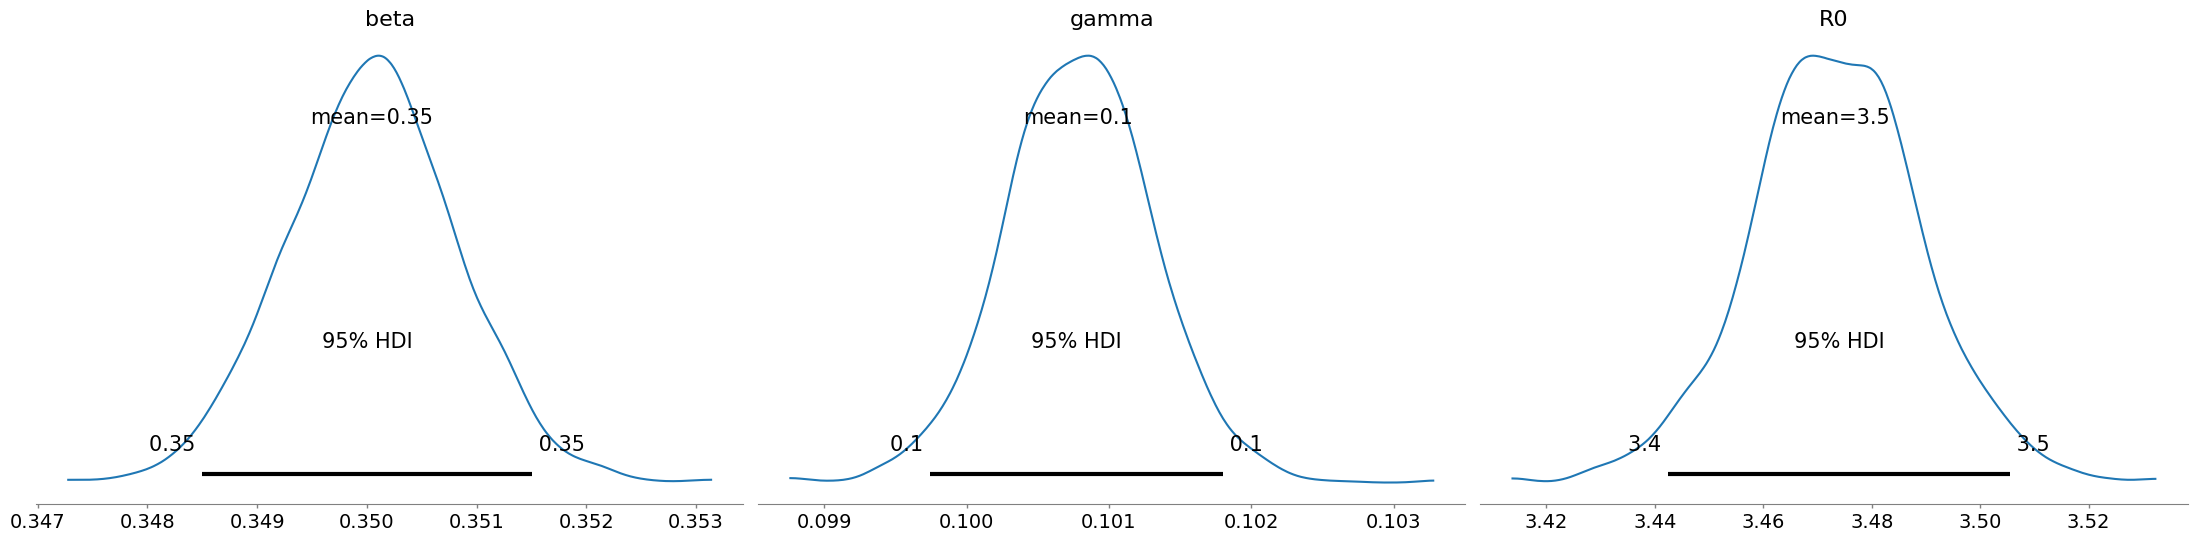

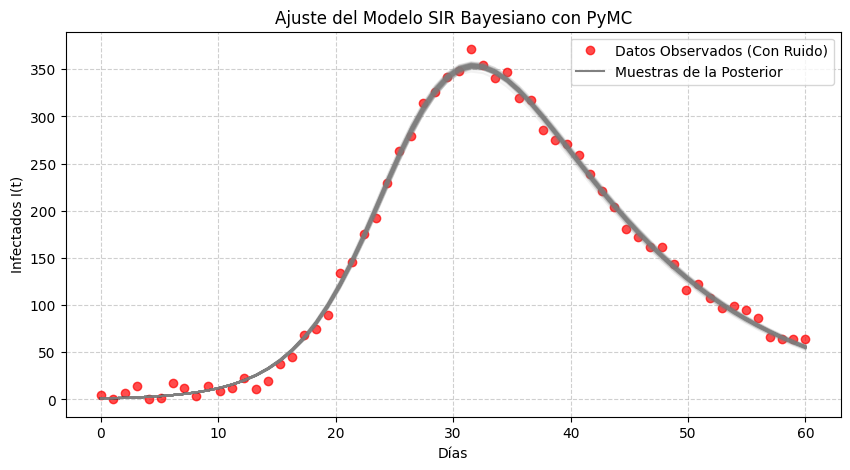

In [4]:
# Resumen estadístico
print(az.summary(trace, var_names=['beta', 'gamma', 'R0']))

# 1. Gráfica de trazas e histogramas
az.plot_trace(trace, var_names=['beta', 'gamma', 'R0'])
plt.tight_layout()
plt.show()

# 2. Intervalos de credibilidad (HDI 95%)
az.plot_posterior(trace, var_names=['beta', 'gamma', 'R0'], hdi_prob=0.95)
plt.tight_layout()
plt.show()

# 3. Gráfica de ajuste predictivo sobre los datos
plt.figure(figsize=(10, 5))
plt.plot(t_eval, obs_infectados, 'ro', label='Datos Observados (Con Ruido)', alpha=0.7)

beta_samples = trace.posterior['beta'].values.flatten()
gamma_samples = trace.posterior['gamma'].values.flatten()

for i in range(100):
    sol_sim = resolver_sir(beta_samples[i], gamma_samples[i])
    plt.plot(t_eval, sol_sim, color='gray', alpha=0.1)

plt.plot([], [], color='gray', label='Muestras de la Posterior')
plt.xlabel('Días')
plt.ylabel('Infectados I(t)')
plt.title('Ajuste del Modelo SIR Bayesiano con PyMC')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()